In [1]:
from pathlib import Path
import urllib.request
import zipfile
import shutil
import pandas as pd
import numpy as np

# Project directories
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)

Project directory: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation
Raw data directory: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\data\raw


In [2]:
zip_path = RAW_DIR / "online_retail_II.zip"

with zipfile.ZipFile(zip_path, "r") as archive:

    excel_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".xlsx")
    ]

    print("Excel files found:", excel_files)

    if not excel_files:
        raise FileNotFoundError(
            "No Excel workbook found inside the downloaded ZIP."
        )

    excel_name = excel_files[0]
    xlsx_path = RAW_DIR / Path(excel_name).name

    with archive.open(excel_name) as source:
        with open(xlsx_path, "wb") as destination:
            shutil.copyfileobj(source, destination)

print("Excel workbook extracted:", xlsx_path)

Excel files found: ['online_retail_II.xlsx']
Excel workbook extracted: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\data\raw\online_retail_II.xlsx


In [3]:
sheets = pd.read_excel(
    xlsx_path,
    sheet_name=None,
    engine="openpyxl"
)

print("Available worksheets:", list(sheets.keys()))

df_raw = pd.concat(
    sheets.values(),
    ignore_index=True
)

print("Dataset downloaded and loaded successfully.")
print("Dataset shape:", df_raw.shape)
print("Original columns:", df_raw.columns.tolist())

Available worksheets: ['Year 2009-2010', 'Year 2010-2011']
Dataset downloaded and loaded successfully.
Dataset shape: (1067371, 8)
Original columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [4]:
raw_file = RAW_DIR / "online_retail_II_raw.csv"

df_raw.to_csv(raw_file, index=False)

print("Raw CSV saved at:", raw_file)

Raw CSV saved at: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\data\raw\online_retail_II_raw.csv


In [5]:
# creating a copy of the original dataset to work on
df = df_raw.copy()

# normalizing variable names for ease of coding
def normalize_column_name(column):
    return (
        str(column)
        .strip()
        .lower()
        .replace(" ", "")
        .replace("_", "")
    )

df.columns = [normalize_column_name(col) for col in df.columns]

# mapping possible source-name variations to standard names
column_mapping = {
    "invoiceno": "InvoiceNo",
    "invoice": "InvoiceNo",
    "stockcode": "StockCode",
    "description": "Description",
    "quantity": "Quantity",
    "invoicedate": "InvoiceDate",
    "unitprice": "UnitPrice",
    "price": "UnitPrice",
    "customerid": "CustomerID",
    "country": "Country"
}

df = df.rename(columns=column_mapping)

print("Standardized columns:")
print(df.columns.tolist())

Standardized columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [6]:
print("First five records:")
display(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nData types and non-null counts:")
df.info()

print("\nNumerical summary:")
numerical_columns = ["Quantity", "UnitPrice"]
numerical_summary = df[numerical_columns].describe().T
display(numerical_summary)

First five records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



Dataset dimensions:
(1067371, 8)

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   InvoiceNo    1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   UnitPrice    1067371 non-null  float64       
 6   CustomerID   824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Quantity,1067371.0,9.938898,172.705794,-80995.00,1.00,3.0,10.00,80995.0
UnitPrice,1067371.0,4.649388,123.553059,-53594.36,1.25,2.1,4.15,38970.0


In [7]:
# identifying missing values
print("Missing values by column:")
display(df.isnull().sum().sort_values(ascending=False))

# duplicate rows
print("\nNumber of exact duplicate rows:")
print(df.duplicated().sum())

# parse dates in the working copy only
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

print("\nDate range:")
print("Earliest:", df["InvoiceDate"].min())
print("Latest:", df["InvoiceDate"].max())

# Cancellation invoices: invoice numbers beginning with C
cancellation_mask = (
    df["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

print("\nCancellation rows:", cancellation_mask.sum())

# quantity and price diagnostics
print("Rows with negative quantity:", (df["Quantity"] < 0).sum())
print("Rows with zero quantity:", (df["Quantity"] == 0).sum())
print("Rows with negative unit price:", (df["UnitPrice"] < 0).sum())
print("Rows with zero unit price:", (df["UnitPrice"] == 0).sum())

# customer coverage
print("\nUnique customers:", df["CustomerID"].nunique())
print("Rows with missing CustomerID:", df["CustomerID"].isna().sum())

# number of countries
print("Unique countries:", df["Country"].nunique())

Missing values by column:


CustomerID     243007
Description      4382
StockCode           0
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64


Number of exact duplicate rows:
34335

Date range:
Earliest: 2009-12-01 07:45:00
Latest: 2011-12-09 12:50:00

Cancellation rows: 19494
Rows with negative quantity: 22950
Rows with zero quantity: 0
Rows with negative unit price: 5
Rows with zero unit price: 6202

Unique customers: 5942
Rows with missing CustomerID: 243007
Unique countries: 43


In [8]:
# identifying cancellation invoices
cancellation_mask = (
    df["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

# identifying negative quantities
negative_quantity_mask = df["Quantity"] < 0

# comparing both conditions
cancellation_comparison = pd.crosstab(
    cancellation_mask,
    negative_quantity_mask,
    rownames=["Cancellation Invoice"],
    colnames=["Negative Quantity"]
)

display(cancellation_comparison)

Negative Quantity,False,True
Cancellation Invoice,,
False,1044420,3457
True,1,19493


In [9]:
# identifying every row involved in an exact duplicate
duplicate_mask = df.duplicated(keep=False)

duplicate_records = df.loc[duplicate_mask].copy()

print("Rows involved in exact duplicates:",
      duplicate_records.shape[0])

print("\nFirst 20 duplicate records:")
display(duplicate_records.head(20))

print("\nNumber of duplicate groups by invoice:")
display(
    duplicate_records.groupby("InvoiceNo")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Rows involved in exact duplicates: 67242

First 20 duplicate records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom



Number of duplicate groups by invoice:


InvoiceNo
537434    1350
538071    1304
537638    1202
537237    1194
536876    1186
536592    1184
537823    1182
537240    1136
537666    1072
536544    1054
dtype: int64

In [10]:
missing_customer_mask = df["CustomerID"].isna()

print("Missing CustomerID rows:",
      missing_customer_mask.sum())

print("\nMissing CustomerID by cancellation status:")

display(
    pd.crosstab(
        missing_customer_mask,
        cancellation_mask,
        rownames=["CustomerID Missing"],
        colnames=["Cancellation Invoice"]
    )
)

print("\nSample records with missing CustomerID:")

display(
    df.loc[missing_customer_mask].head(10)
)

Missing CustomerID rows: 243007

Missing CustomerID by cancellation status:


Cancellation Invoice,False,True
CustomerID Missing,,
False,805620,18744
True,242257,750



Sample records with missing CustomerID:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


In [11]:
# identifying missing descriptions
missing_description_mask = df["Description"].isna()

print("Rows with missing descriptions:",
      missing_description_mask.sum())

print("\nSample records:")
display(
    df.loc[
        missing_description_mask,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "CustomerID"]
    ].head(20)
)

print("\nUnique StockCodes with missing descriptions:",
      df.loc[missing_description_mask, "StockCode"].nunique())

Rows with missing descriptions: 4382

Sample records:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
470,489521,21646,NaN,-50,0.0,NaN
3114,489655,20683,NaN,-44,0.0,NaN
3161,489659,21350,NaN,230,0.0,NaN
3731,489781,84292,NaN,17,0.0,NaN
4296,489806,18010,NaN,-770,0.0,NaN
4566,489821,85049G,NaN,-240,0.0,NaN
6378,489882,35751C,NaN,12,0.0,NaN
6555,489898,79323G,NaN,954,0.0,NaN
6576,489901,21098,NaN,-200,0.0,NaN
6581,489903,21166,NaN,48,0.0,NaN



Unique StockCodes with missing descriptions: 2451


In [12]:
# identifying zero unit prices
zero_price_records = df[df["UnitPrice"] == 0]

print("Zero-price records:")
display(zero_price_records.head(15))

# identifying negative unit prices
negative_price_records = df[df["UnitPrice"] < 0]

print("\nNegative-price records:")
display(negative_price_records)

Zero-price records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom



Negative-price records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [13]:
# counting duplicate rows under two different definitions
print("Additional duplicate copies:",
      df.duplicated().sum())

print("All rows belonging to duplicate groups:",
      df.duplicated(keep=False).sum())

# inspecting the largest duplicate groups
duplicate_group_sizes = (
    df.groupby(list(df.columns), dropna=False)
      .size()
      .reset_index(name="Occurrences")
      .query("Occurrences > 1")
      .sort_values("Occurrences", ascending=False)
)

print("\nLargest exact duplicate groups:")
display(duplicate_group_sizes.head(15))

Additional duplicate copies: 34335
All rows belonging to duplicate groups: 67242

Largest exact duplicate groups:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Occurrences
694118,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,20
694117,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,12
496282,537224,70007,HI TEC ALPINE HAND WARMER,1,2010-12-05 16:24:00,1.65,13174.0,United Kingdom,10
895184,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102.0,United Kingdom,8
495167,537154,22727,ALARM CLOCK BAKELIKE RED,1,2010-12-05 13:05:00,3.75,15808.0,United Kingdom,6
512230,538514,21756,BATH BUILDING BLOCK WORD,1,2010-12-12 14:27:00,5.95,15044.0,United Kingdom,6
497951,537265,79000,MOROCCAN TEA GLASS,12,2010-12-06 11:26:00,0.85,15919.0,United Kingdom,6
495877,537208,90082B,DIAMANTE BOW BROOCH RED COLOUR,1,2010-12-05 15:12:00,6.35,15889.0,United Kingdom,6
357161,525065,20894,HANGING BAUBLE T-LIGHT HOLDER LARGE,1,2010-10-03 14:28:00,2.95,16799.0,United Kingdom,6
503982,537781,22898,CHILDRENS APRON APPLES DESIGN,1,2010-12-08 12:46:00,1.95,17341.0,United Kingdom,6


In [14]:
# identifying negative quantities not associated with cancellation invoices
unusual_negative_records = df[
    (df["Quantity"] < 0) &
    (~cancellation_mask)
]

print("Negative quantities outside cancellation invoices:",
      len(unusual_negative_records))

print("\nCustomerID availability:")
print(unusual_negative_records["CustomerID"].isna().value_counts())

print("\nSample records:")
display(unusual_negative_records.head(20))

print("\nDescriptions of these records:")
display(
    unusual_negative_records["Description"]
    .value_counts(dropna=False)
    .head(20)
)

Negative quantities outside cancellation invoices: 3457

CustomerID availability:
CustomerID
True    3457
Name: count, dtype: int64

Sample records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom



Descriptions of these records:


Description
NaN                       2689
check                      123
damages                     84
?                           83
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
smashed                      9
thrown away                  9
Unsaleable, destroyed.       9
dotcom                       8
damages?                     7
??                           7
crushed                      6
given away                   6
MIA                          5
Damages                      5
counted                      5
checked                      5
Name: count, dtype: int64

In [15]:
zero_price_records = df[df["UnitPrice"] == 0].copy()

print("Total zero-price records:", len(zero_price_records))

print("\nQuantity classification:")
display(
    zero_price_records["Quantity"]
    .apply(
        lambda x: "Positive" if x > 0
        else "Negative" if x < 0
        else "Zero"
    )
    .value_counts()
)

print("\nCustomerID availability:")
print(zero_price_records["CustomerID"].isna().value_counts())

print("\nTop descriptions:")
display(
    zero_price_records["Description"]
    .value_counts(dropna=False)
    .head(20)
)

print("\nZero-price records with identified customers:")
display(
    zero_price_records[
        zero_price_records["CustomerID"].notna()
    ].head(20)
)

Total zero-price records: 6202

Quantity classification:


Quantity
Negative    3457
Positive    2745
Name: count, dtype: int64


CustomerID availability:
CustomerID
True     6131
False      71
Name: count, dtype: int64

Top descriptions:


Description
NaN                              4382
check                             162
?                                  92
damages                            84
damaged                            81
found                              28
missing                            27
sold as set on dotcom              20
Damaged                            17
adjustment                         16
OWL DOORSTOP                       15
POLYESTER FILLER PAD 45x45cm       12
dotcom                             12
amazon                             11
POLYESTER FILLER PAD 40x40cm       10
IVORY KITCHEN SCALES               10
FRENCH BLUE METAL DOOR SIGN 1      10
smashed                             9
Found                               9
PICNIC BASKET WICKER LARGE          9
Name: count, dtype: int64


Zero-price records with identified customers:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,2009-12-15 13:49:00,0.0,15070.0,United Kingdom
40101,492760,21143,ANTIQUE GLASS HEART DECORATION,12,2009-12-18 14:22:00,0.0,18071.0,United Kingdom
47126,493761,79320,FLAMINGO LIGHTS,24,2010-01-06 14:54:00,0.0,14258.0,United Kingdom
48342,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,2010-01-08 10:43:00,0.0,12417.0,Belgium
57619,494607,21533,RETRO SPOT LARGE MILK JUG,12,2010-01-15 12:43:00,0.0,16858.0,United Kingdom


In [16]:

# removing exact duplicate rows

df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after duplicate removal:", len(df_clean))
print("Duplicate copies removed:", len(df) - len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())


Original rows: 1067371
Rows after duplicate removal: 1033036
Duplicate copies removed: 34335
Remaining exact duplicates: 0


In [17]:

# identifying valid purchase transactions

# identifying cancellation invoices
cancellation_mask = (
    df_clean["InvoiceNo"].astype(str).str.upper().str.startswith("C")
)

# define valid purchase conditions
valid_purchase_mask = (
    (~cancellation_mask) &
    (df_clean["CustomerID"].notna()) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
)

# creating purchase dataset
purchase_df = df_clean.loc[valid_purchase_mask].copy()

# computing line-level revenue
purchase_df["TotalPrice"] = (
    purchase_df["Quantity"] * purchase_df["UnitPrice"]
)

print("Valid purchase rows:", len(purchase_df))
print("Unique customers:", purchase_df["CustomerID"].nunique())
print("Unique invoices:", purchase_df["InvoiceNo"].nunique())
print("Total positive sales value:", purchase_df["TotalPrice"].sum())

display(purchase_df.head())


Valid purchase rows: 779425
Unique customers: 5878
Unique invoices: 36969
Total positive sales value: 17374804.268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [18]:

# validating the cleaned purchase dataset

print("Missing CustomerID:",
      purchase_df["CustomerID"].isna().sum())

print("Cancellation invoices:",
      purchase_df["InvoiceNo"].astype(str)
      .str.upper().str.startswith("C").sum())

print("Non-positive quantities:",
      (purchase_df["Quantity"] <= 0).sum())

print("Non-positive unit prices:",
      (purchase_df["UnitPrice"] <= 0).sum())

print("Missing InvoiceDate:",
      purchase_df["InvoiceDate"].isna().sum())

print("Missing Description:",
      purchase_df["Description"].isna().sum())


Missing CustomerID: 0
Cancellation invoices: 0
Non-positive quantities: 0
Non-positive unit prices: 0
Missing InvoiceDate: 0
Missing Description: 0


In [19]:
from pathlib import Path

# identifying the project root
project_root = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# saving cleaned purchase transactions
purchase_path = processed_dir / "cleaned_purchases.csv"
purchase_df.to_csv(purchase_path, index=False)

print("Saved to:", purchase_path)
print("File size (MB):", round(purchase_path.stat().st_size / (1024**2), 2))

Saved to: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\data\processed\cleaned_purchases.csv
File size (MB): 73.64


In [20]:
# Reference date: one day after the latest date in the original dataset
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

print("RFM Reference Date:", reference_date)

# group transactions by customer
rfm = (
    purchase_df.groupby("CustomerID")
    .agg(
        LastPurchaseDate=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalPrice", "sum")
    )
)

# computing customer recency
rfm["Recency"] = (
    reference_date - rfm["LastPurchaseDate"]
).dt.days

rfm = rfm[["Recency", "Frequency", "Monetary"]]

# sort by customer ID
rfm = rfm.sort_index()

display(rfm.head(10))

print("\nRFM dataset shape:", rfm.shape)
print("Unique customers:", rfm.index.nunique())
print("Reference date:", reference_date)

RFM Reference Date: 2011-12-10 00:00:00


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,18,4,4428.69
12350.0,310,1,334.40
12351.0,375,1,300.93
12352.0,36,10,2849.84
12353.0,204,2,406.76
12354.0,232,1,1079.40



RFM dataset shape: (5878, 3)
Unique customers: 5878
Reference date: 2011-12-10 00:00:00


In [21]:
print("Missing values:")
print(rfm.isna().sum())

print("\nDuplicate customer IDs:", rfm.index.duplicated().sum())

print("\nRFM descriptive statistics:")
display(rfm.describe().T)

print("\nMinimum Recency:", rfm["Recency"].min())
print("Minimum Frequency:", rfm["Frequency"].min())
print("Minimum Monetary:", rfm["Monetary"].min())

print("\nTotal RFM Monetary:", round(rfm["Monetary"].sum(), 2))
print("Total transaction sales:", round(purchase_df["TotalPrice"].sum(), 2))

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Duplicate customer IDs: 0

RFM descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,5878.0,200.866791,209.353961,0.00,25.00,95.00,379.000,738.00
Frequency,5878.0,6.289384,13.009406,1.00,1.00,3.00,7.000,398.00
Monetary,5878.0,2955.904095,14440.852688,2.95,342.28,867.74,2248.305,580987.04



Minimum Recency: 0
Minimum Frequency: 1
Minimum Monetary: 2.95

Total RFM Monetary: 17374804.27
Total transaction sales: 17374804.27


In [22]:
rfm_path = processed_dir / "customer_rfm.csv"

rfm.to_csv(rfm_path, index=True)

print("RFM dataset saved to:", rfm_path)

RFM dataset saved to: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\data\processed\customer_rfm.csv


In [23]:

# calculating skewness for RFM variables

skewness = rfm[["Recency", "Frequency", "Monetary"]].skew()

print("Skewness of RFM variables:")
display(skewness.to_frame(name="Skewness"))

print("\nTransformation recommendation:")
for column, value in skewness.items():
    if value > 1:
        print(f"{column}: Right-skewed (skewness = {value:.3f}) - Log transformation recommended")
    elif value < -1:
        print(f"{column}: Left-skewed (skewness = {value:.3f})")
    else:
        print(f"{column}: Skewness within -1 to 1 (skewness = {value:.3f})")


Skewness of RFM variables:


,Skewness
Recency,0.887194
Frequency,12.639951
Monetary,25.070190



Transformation recommendation:
Recency: Skewness within -1 to 1 (skewness = 0.887)
Frequency: Right-skewed (skewness = 12.640) - Log transformation recommended
Monetary: Right-skewed (skewness = 25.070) - Log transformation recommended


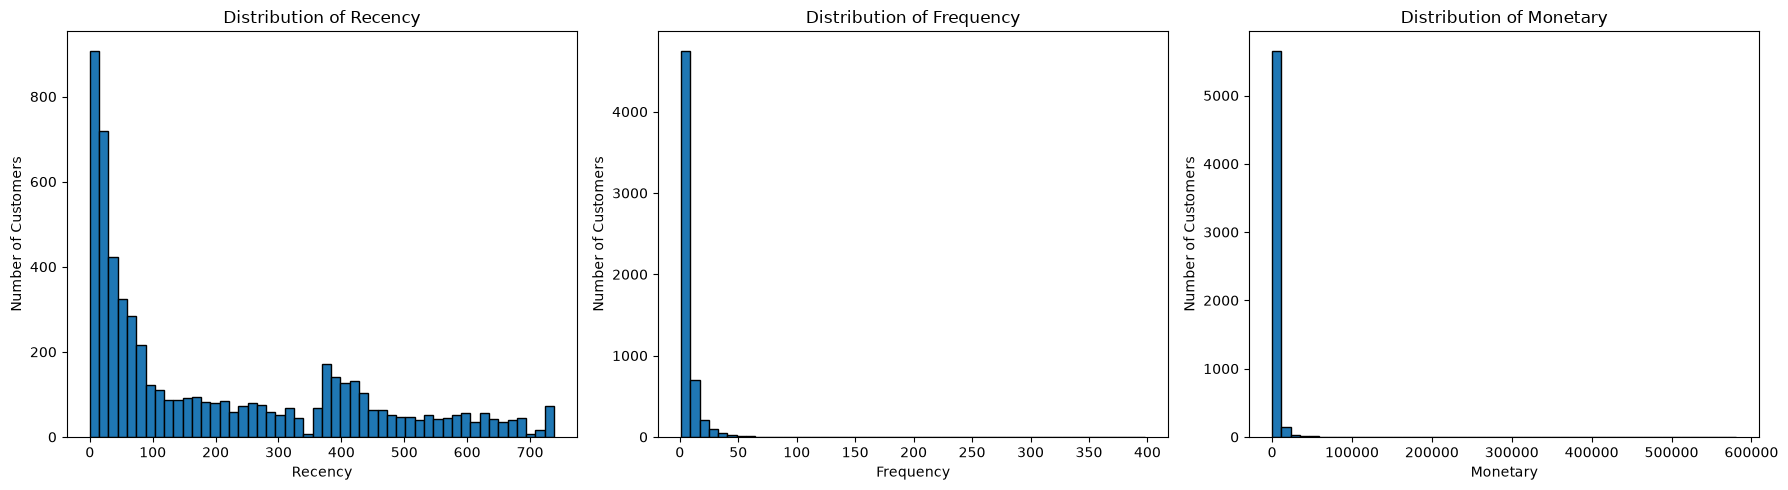

In [24]:

# histograms for Recency, Frequency, and Monetary values

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, column in enumerate(["Recency", "Frequency", "Monetary"]):
    axes[i].hist(rfm[column], bins=50, edgecolor="black")
    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


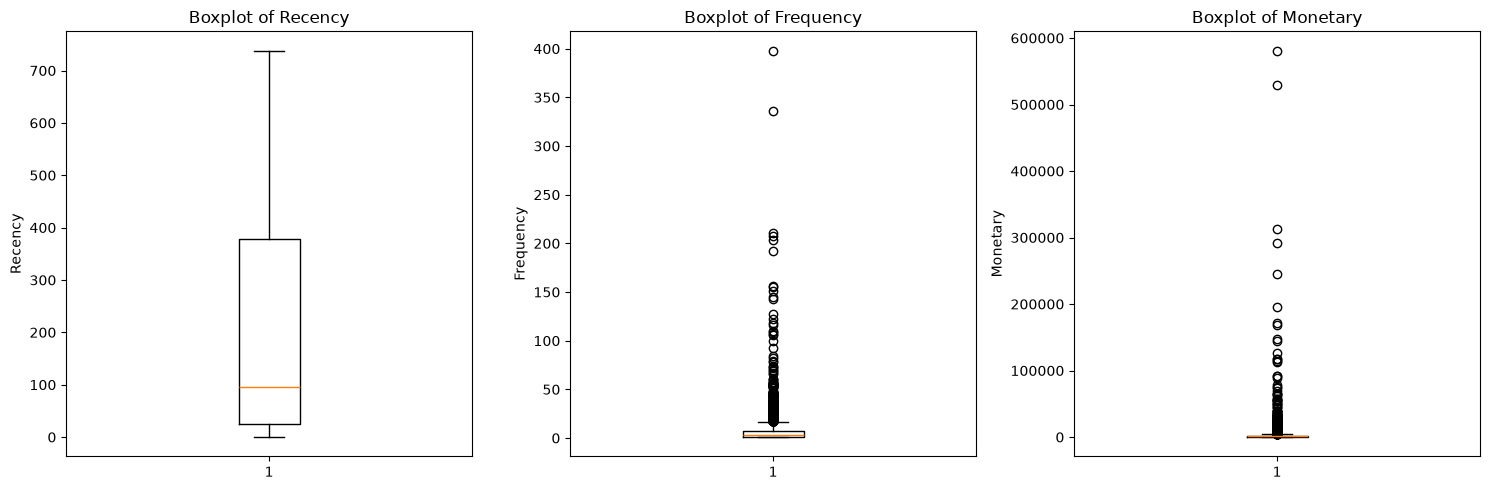

In [25]:

# boxplots of RFM variables

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, column in enumerate(["Recency", "Frequency", "Monetary"]):
    axes[i].boxplot(rfm[column])
    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_ylabel(column)

plt.tight_layout()
plt.show()


Estimated Box-Cox Lambda Values:
{'Frequency': np.float64(-0.2745131458318828), 'Monetary': np.float64(-0.05374579458296211)}

First five transformed observations:


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1.801246,8.446916
12347.0,2,1.584427,6.824062
12348.0,75,1.300956,6.246242
12349.0,18,1.153018,6.757056
12350.0,310,0.000000,4.992073


,Original Skewness,Box-Cox Skewness
Recency,0.887194,0.887194
Frequency,12.639951,0.095706
Monetary,25.070190,-0.008411


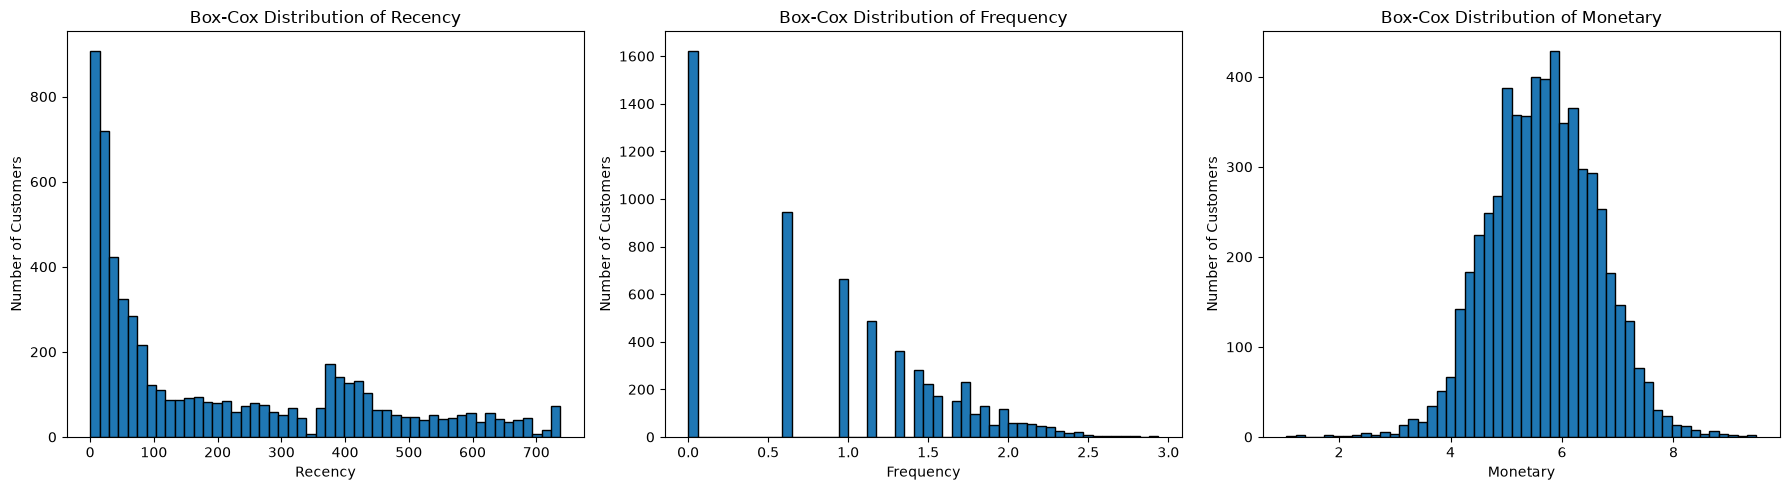

In [26]:
from scipy.stats import boxcox

# Create a separate copy
rfm_boxcox = rfm.copy()

# Store estimated lambda values
boxcox_lambdas = {}

# Apply Box-Cox only to variables with skewness > 1
for column in ["Frequency", "Monetary"]:

    transformed_values, fitted_lambda = boxcox(
        rfm[column]
    )

    rfm_boxcox[column] = transformed_values

    boxcox_lambdas[column] = fitted_lambda

print("Estimated Box-Cox Lambda Values:")
print(boxcox_lambdas)

print("\nFirst five transformed observations:")
display(rfm_boxcox.head())

skewness_boxcox = rfm_boxcox.skew()

comparison = pd.DataFrame({
    "Original Skewness": rfm.skew(),
    "Box-Cox Skewness": skewness_boxcox
})

display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, column in enumerate(["Recency", "Frequency", "Monetary"]):

    axes[i].hist(
        rfm_boxcox[column],
        bins=50,
        edgecolor="black"
    )

    axes[i].set_title(f"Box-Cox Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [27]:
kurtosis_comparison = pd.DataFrame({
    "Original Kurtosis": rfm.kurt(),
    "Box-Cox Kurtosis": rfm_boxcox.kurt()
})

print("Kurtosis comparison (excess kurtosis):")
display(kurtosis_comparison)

Kurtosis comparison (excess kurtosis):


,Original Kurtosis,Box-Cox Kurtosis
Recency,-0.476937,-0.476937
Frequency,266.729382,-1.061953
Monetary,830.167745,0.363852


In [28]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform the Box-Cox transformed RFM data
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_boxcox),
    columns=rfm_boxcox.columns,
    index=rfm_boxcox.index
)

print("Standardized RFM dataset:")
display(rfm_scaled.head())

print("\nShape of standardized dataset:")
print(rfm_scaled.shape)

print("\nMean of standardized variables:")
display(rfm_scaled.mean())

print("\nStandard deviation of standardized variables:")
display(rfm_scaled.std(ddof=0))

# Checking whether the standardized data has approximately zero mean
# and unit population standard deviation.

validation = pd.DataFrame({
    "Mean": rfm_scaled.mean(),
    "Standard Deviation": rfm_scaled.std(ddof=0),
    "Minimum": rfm_scaled.min(),
    "Maximum": rfm_scaled.max()
})

display(validation)

Standardized RFM dataset:


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,0.592985,1.236195,2.896959
12347.0,-0.949988,0.930737,1.203960
12348.0,-0.601266,0.531378,0.601164
12349.0,-0.873556,0.322962,1.134058
12350.0,0.521330,-1.301428,-0.707214



Shape of standardized dataset:
(5878, 3)

Mean of standardized variables:


Recency      1.692344e-17
Frequency   -8.522161e-17
Monetary    -9.670537e-18
dtype: float64


Standard deviation of standardized variables:


Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64

,Mean,Standard Deviation,Minimum,Maximum
Recency,1.692344e-17,1.0,-0.959542,2.565888
Frequency,-8.522161e-17,1.0,-1.301428,2.838446
Monetary,-9.670537e-18,1.0,-4.818680,3.984113


In [29]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

# Initialize PCA with all available components
pca_full = PCA(n_components=3)

# Fit PCA and transform standardized RFM data
pca_scores_full = pca_full.fit_transform(rfm_scaled)

print("PCA transformation completed.")

print("\nShape of PCA-transformed dataset:")
print(pca_scores_full.shape)

print("\nExplained Variance Ratio:")
print(pca_full.explained_variance_ratio_)

print("\nEigenvalues:")
print(pca_full.explained_variance_)

# Calculate individual and cumulative explained variance
explained_variance = pca_full.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

pca_variance_table = pd.DataFrame({
    "Principal Component": ["PC1", "PC2", "PC3"],
    "Eigenvalue": pca_full.explained_variance_,
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

print("PCA Explained Variance Analysis:")
display(pca_variance_table)

# Determine number of components required to explain at least 80%
components_80 = np.argmax(cumulative_variance >= 0.80) + 1

print(
    f"\nNumber of components required to explain "
    f"at least 80% variance: {components_80}"
)

PCA transformation completed.

Shape of PCA-transformed dataset:
(5878, 3)

Explained Variance Ratio:
[0.75156493 0.19566056 0.05277451]

Eigenvalues:
[2.25507844 0.58708155 0.15835048]
PCA Explained Variance Analysis:


,Principal Component,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,PC1,2.255078,75.156493,75.156493
1,PC2,0.587082,19.566056,94.722549
2,PC3,0.158350,5.277451,100.000000



Number of components required to explain at least 80% variance: 2


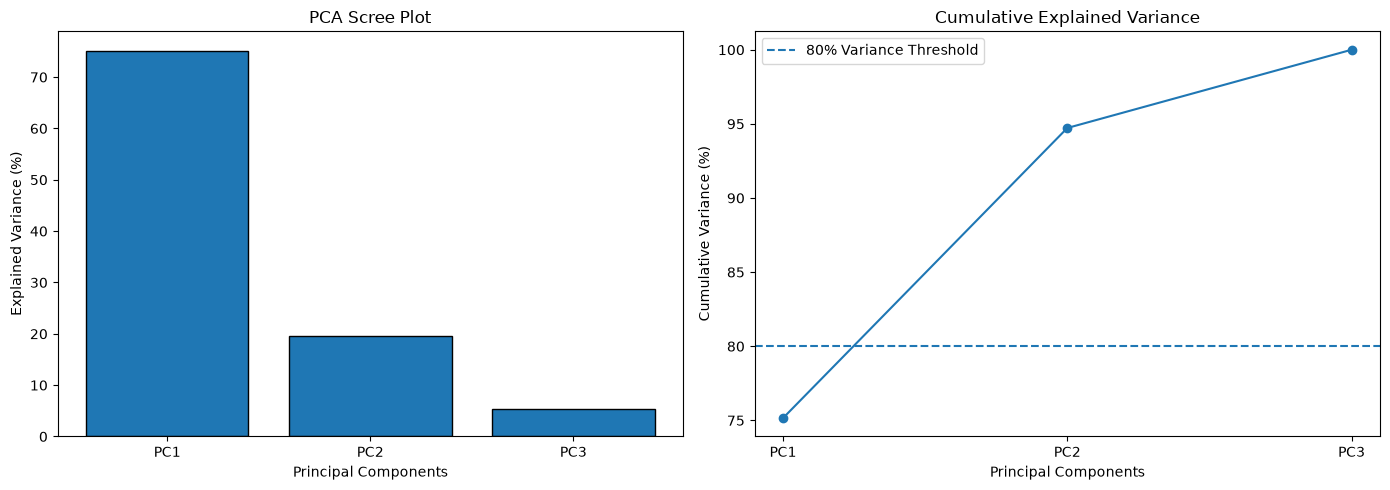

In [30]:
import matplotlib.pyplot as plt

components = ["PC1", "PC2", "PC3"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].bar(
    components,
    explained_variance * 100,
    edgecolor="black"
)

axes[0].set_title("PCA Scree Plot")
axes[0].set_xlabel("Principal Components")
axes[0].set_ylabel("Explained Variance (%)")

# Cumulative explained variance
axes[1].plot(
    components,
    cumulative_variance * 100,
    marker="o"
)

axes[1].axhline(
    y=80,
    linestyle="--",
    label="80% Variance Threshold"
)

axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Principal Components")
axes[1].set_ylabel("Cumulative Variance (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [31]:
pca_loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=["PC1", "PC2", "PC3"],
    index=rfm_scaled.columns
)

print("PCA Component Loadings:")
display(pca_loadings)

PCA Component Loadings:


,PC1,PC2,PC3
Recency,-0.498965,0.863675,0.071407
Frequency,0.619176,0.297633,0.726661
Monetary,0.606346,0.406792,-0.683275


In [32]:
# Extracting the first two principal components
pca_scores = pd.DataFrame(
    pca_scores_full[:, :2],
    columns=["PC1", "PC2"],
    index=rfm_scaled.index
)

print("Two-dimensional PCA dataset:")
display(pca_scores.head())

print("\nDataset shape:")
print(pca_scores.shape)

print("\nCheck for missing values:")
print(pca_scores.isnull().sum())

Two-dimensional PCA dataset:


,PC1,PC2
CustomerID,,
12346.0,2.226103,2.058539
12347.0,1.780317,-0.053702
12348.0,0.993541,-0.116594
12349.0,1.323475,-0.197019
12350.0,-1.494754,-0.224777



Dataset shape:
(5878, 2)

Check for missing values:
PC1    0
PC2    0
dtype: int64


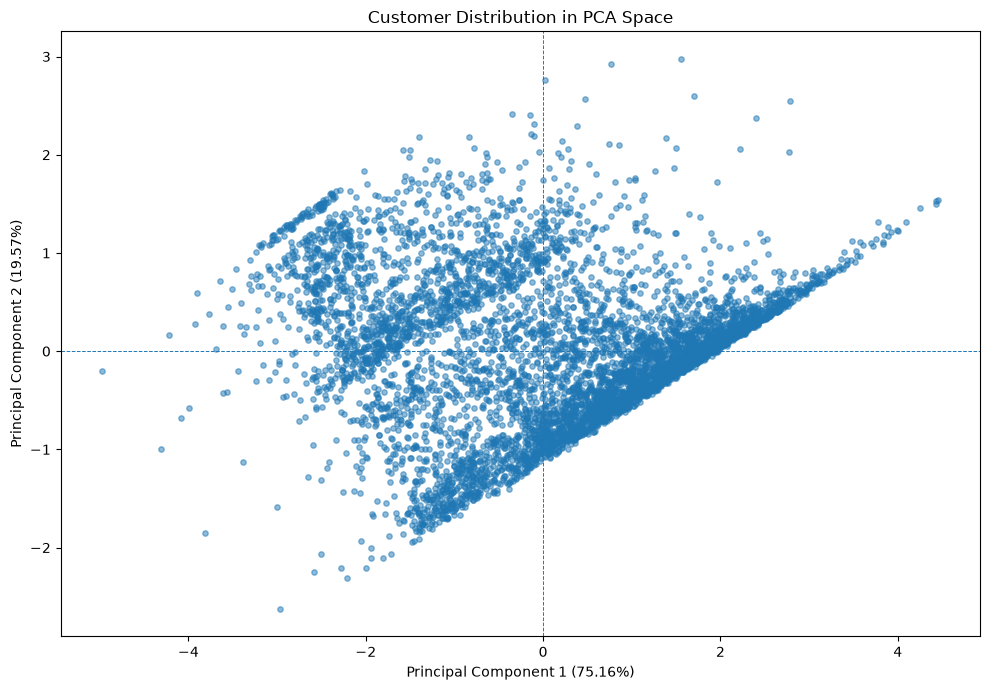

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    alpha=0.5,
    s=15
)

plt.title("Customer Distribution in PCA Space")
plt.xlabel("Principal Component 1 (75.16%)")
plt.ylabel("Principal Component 2 (19.57%)")

plt.axhline(0, linestyle="--", linewidth=0.7)
plt.axvline(0, linestyle="--", linewidth=0.7)

plt.tight_layout()
plt.show()

In [34]:
pca_path = processed_dir / "customer_pca_scores.csv"

pca_scores.to_csv(pca_path, index=True)

print(f"PCA scores saved to: {pca_path}")

PCA scores saved to: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\data\processed\customer_pca_scores.csv


In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

# using the two-dimensional PCA dataset
X_pca = pca_scores.copy()

# clustering evaluation results
wcss = []
silhouette_scores = []

# testing cluster counts from 2 to 10
k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    cluster_labels = kmeans.fit_predict(X_pca)

    # Within-cluster sum of squares
    wcss.append(kmeans.inertia_)

    # Silhouette score
    sil_score = silhouette_score(
        X_pca,
        cluster_labels
    )

    silhouette_scores.append(sil_score)

    print(
        f"K = {k} | "
        f"WCSS = {kmeans.inertia_:.2f} | "
        f"Silhouette Score = {sil_score:.4f}"
    )

K = 2 | WCSS = 7449.36 | Silhouette Score = 0.4729
K = 3 | WCSS = 4919.16 | Silhouette Score = 0.4276
K = 4 | WCSS = 3659.53 | Silhouette Score = 0.4003
K = 5 | WCSS = 2648.91 | Silhouette Score = 0.4326
K = 6 | WCSS = 2196.35 | Silhouette Score = 0.4112
K = 7 | WCSS = 1884.89 | Silhouette Score = 0.4027
K = 8 | WCSS = 1657.93 | Silhouette Score = 0.4038
K = 9 | WCSS = 1451.74 | Silhouette Score = 0.3893
K = 10 | WCSS = 1313.78 | Silhouette Score = 0.3981


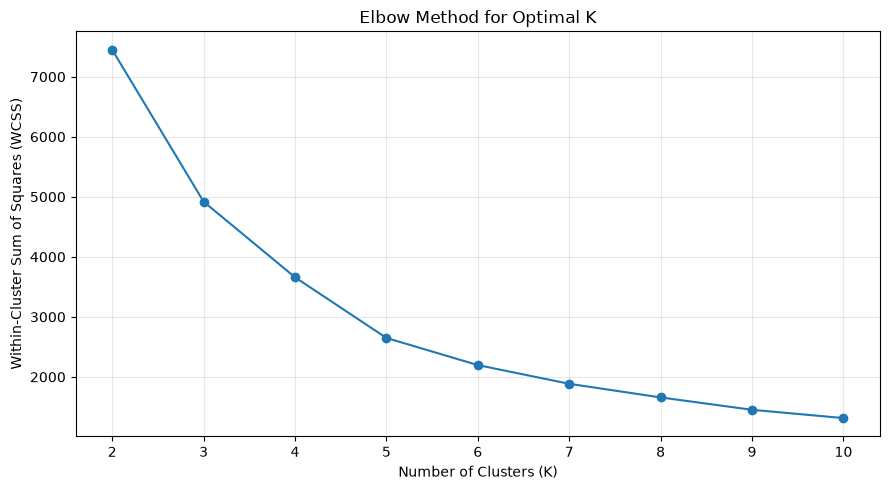

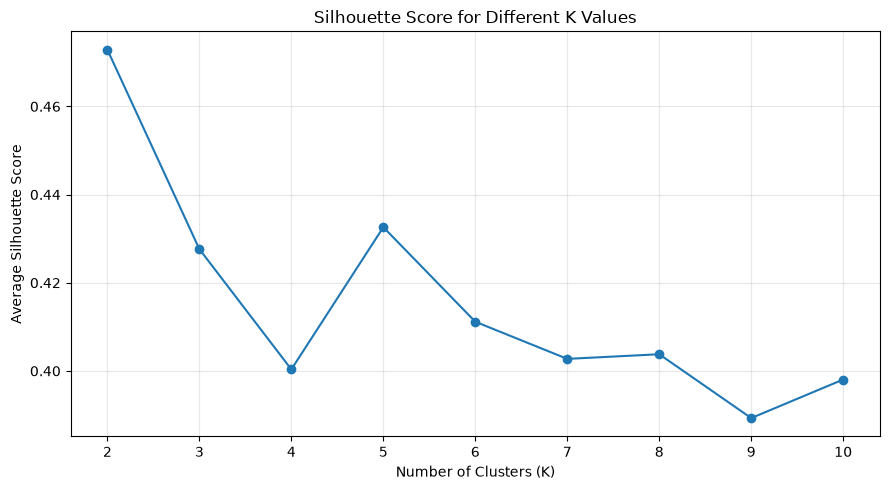

In [36]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
kmeans_evaluation = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "WCSS": wcss,
    "Silhouette Score": silhouette_scores
})

display(kmeans_evaluation)

best_silhouette_k = list(k_values)[
    silhouette_scores.index(max(silhouette_scores))
]

print(
    f"Highest average silhouette score occurs at K = "
    f"{best_silhouette_k}"
)

,Number of Clusters,WCSS,Silhouette Score
0,2,7449.359518,0.472855
1,3,4919.159612,0.427627
2,4,3659.527292,0.400346
3,5,2648.910008,0.432608
4,6,2196.347383,0.411157
5,7,1884.885963,0.402734
6,8,1657.929599,0.403784
7,9,1451.741870,0.389304
8,10,1313.780583,0.398053


Highest average silhouette score occurs at K = 2


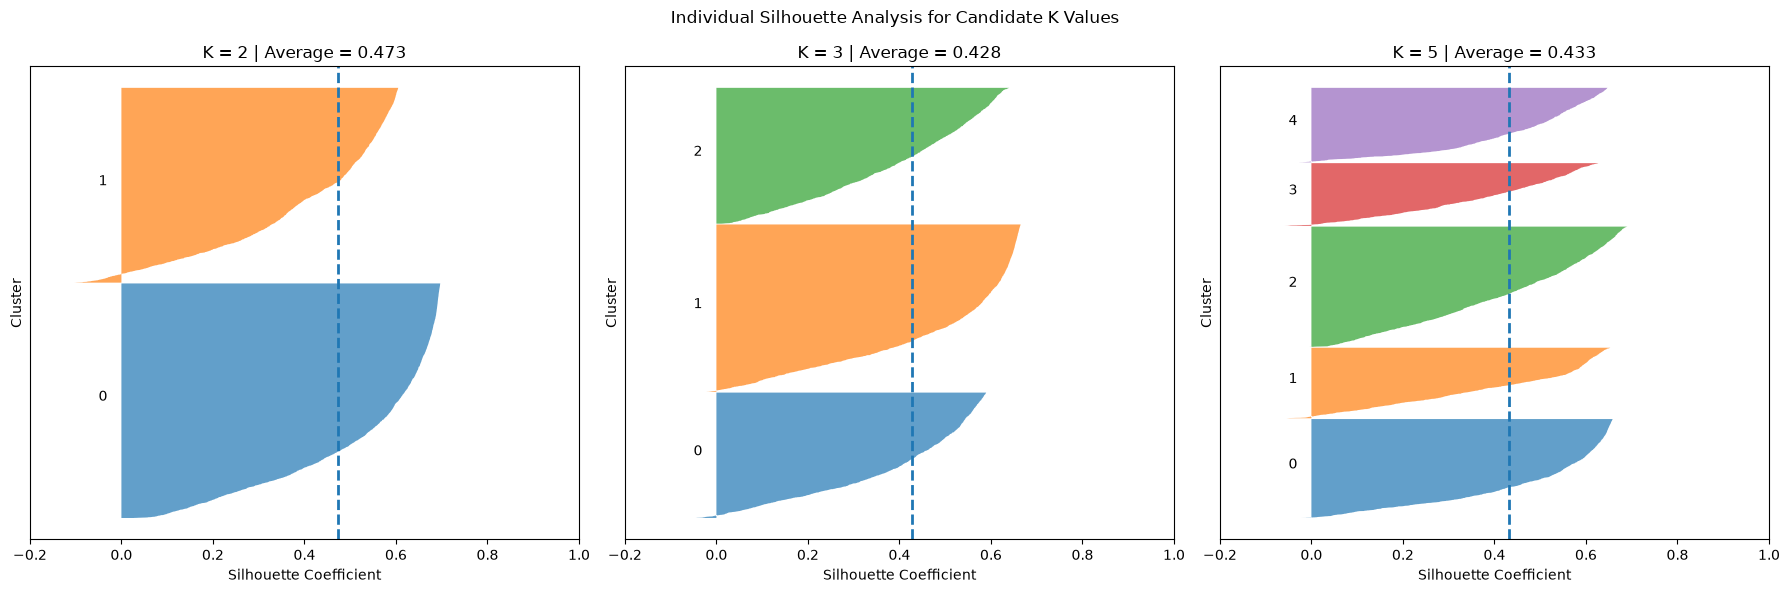

In [38]:
from sklearn.metrics import silhouette_samples
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt

candidate_k = [2, 3, 5]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

for ax, k in zip(axes, candidate_k):

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_pca)

    sample_silhouette_values = silhouette_samples(
        X_pca,
        labels
    )

    y_lower = 10

    for i in range(k):

        cluster_silhouette_values = (
            sample_silhouette_values[labels == i]
        )

        cluster_silhouette_values.sort()

        cluster_size = len(cluster_silhouette_values)

        y_upper = y_lower + cluster_size

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_silhouette_values,
            alpha=0.7
        )

        ax.text(
            -0.05,
            y_lower + cluster_size / 2,
            str(i)
        )

        y_lower = y_upper + 10

    average_score = np.mean(sample_silhouette_values)

    ax.axvline(
        average_score,
        linestyle="--",
        linewidth=2
    )

    ax.set_title(
        f"K = {k} | Average = {average_score:.3f}"
    )

    ax.set_xlabel("Silhouette Coefficient")
    ax.set_ylabel("Cluster")

    ax.set_xlim([-0.2, 1])
    ax.set_yticks([])

plt.suptitle(
    "Individual Silhouette Analysis for Candidate K Values"
)

plt.tight_layout()
plt.show()

In [39]:
candidate_results = {}

for k in [2, 3, 5]:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_pca)

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    candidate_results[k] = cluster_sizes

    print(f"\nCluster sizes for K = {k}")
    display(cluster_sizes.to_frame("Number of Customers"))


Cluster sizes for K = 2


,Number of Customers
0,3211
1,2667



Cluster sizes for K = 3


,Number of Customers
0,1720
1,2295
2,1863



Cluster sizes for K = 5


,Number of Customers
0,1362
1,971
2,1656
3,863
4,1026


In [40]:
from sklearn.cluster import KMeans

candidate_models = {}
candidate_labels = {}

for k in [2, 3, 5]:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_pca)

    candidate_models[k] = model
    candidate_labels[k] = labels

print("Candidate K-Means models fitted successfully.")

Candidate K-Means models fitted successfully.


In [41]:
rfm_candidates = {}

for k in [2, 3, 5]:

    segmented_data = rfm.copy()

    segmented_data["Cluster"] = candidate_labels[k]

    rfm_candidates[k] = segmented_data

    print(f"\nK = {k}")
    display(segmented_data.head())

for k in [2, 3, 5]:

    print(f"\n{'='*45}")
    print(f"RFM PROFILE FOR K = {k}")
    print(f"{'='*45}")

    segmented_data = rfm_candidates[k]

    profile = segmented_data.groupby("Cluster").agg(
        Customer_Count=("Recency", "count"),

        Mean_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),

        Mean_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),

        Mean_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median")
    )

    display(profile.round(2))


K = 2


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,325,12,77556.46,0
12347.0,2,8,4921.53,0
12348.0,75,5,2019.40,0
12349.0,18,4,4428.69,0
12350.0,310,1,334.40,1



K = 3


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,325,12,77556.46,1
12347.0,2,8,4921.53,1
12348.0,75,5,2019.40,1
12349.0,18,4,4428.69,1
12350.0,310,1,334.40,0



K = 5


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,325,12,77556.46,0
12347.0,2,8,4921.53,0
12348.0,75,5,2019.40,2
12349.0,18,4,4428.69,0
12350.0,310,1,334.40,1


... (2 outputs left out)


RFM PROFILE FOR K = 3


,Customer_Count,Mean_Recency,Median_Recency,Mean_Frequency,Median_Frequency,Mean_Monetary,Median_Monetary
Cluster,,,,,,,
0,1720,480.67,448.0,1.64,1.0,501.76,315.17
1,2295,75.24,31.0,13.00,8.0,6689.27,2938.53
2,1863,97.30,64.0,2.32,2.0,622.61,542.04



RFM PROFILE FOR K = 5


,Customer_Count,Mean_Recency,Median_Recency,Mean_Frequency,Median_Frequency,Mean_Monetary,Median_Monetary
Cluster,,,,,,,
0,1362,44.63,22.0,18.01,12.0,10002.29,4631.74
1,971,118.76,79.0,1.36,1.0,315.58,274.15
2,1656,69.09,49.0,4.25,4.0,1262.57,1091.52
3,863,405.50,395.0,3.41,3.0,1262.53,882.46
4,1026,526.55,521.0,1.12,1.0,258.16,216.68


In [42]:
for k in [2, 3, 5]:

    segmented_data = rfm_candidates[k]

    revenue = segmented_data.groupby("Cluster")["Monetary"].sum()

    revenue_percentage = (revenue / revenue.sum()) * 100

    revenue_summary = pd.DataFrame({
        "Customer_Count": segmented_data.groupby("Cluster").size(),
        "Revenue": revenue,
        "Revenue_Contribution_Percent": revenue_percentage
    })

    print(f"\n{'='*20} REVENUE CONTRIBUTION FOR K = {k} {'='*20}")
    display(revenue_summary.round(2))


==================== REVENUE CONTRIBUTION FOR K = 2 ====================


,Customer_Count,Revenue,Revenue_Contribution_Percent
Cluster,,,
0,3211,16186602.22,93.16
1,2667,1188202.05,6.84



==================== REVENUE CONTRIBUTION FOR K = 3 ====================


,Customer_Count,Revenue,Revenue_Contribution_Percent
Cluster,,,
0,1720,863019.36,4.97
1,2295,15351868.75,88.36
2,1863,1159916.15,6.68



==================== REVENUE CONTRIBUTION FOR K = 5 ====================


,Customer_Count,Revenue,Revenue_Contribution_Percent
Cluster,,,
0,1362,13623120.59,78.41
1,971,306431.63,1.76
2,1656,2090808.50,12.03
3,863,1089566.30,6.27
4,1026,264877.25,1.52


In [43]:
# Calculating the time between consecutive purchases
# for each customer using distinct invoice dates.

customer_invoice_dates = (
    purchase_df[["CustomerID", "InvoiceNo", "InvoiceDate"]]
    .drop_duplicates(subset=["CustomerID", "InvoiceNo"])
    .sort_values(["CustomerID", "InvoiceDate"])
    .copy()
)

customer_invoice_dates["Days_Between_Purchases"] = (
    customer_invoice_dates
    .groupby("CustomerID")["InvoiceDate"]
    .diff()
    .dt.total_seconds() / 86400
)

# Calculating average and median IPT per customer
ipt = (
    customer_invoice_dates
    .groupby("CustomerID")["Days_Between_Purchases"]
    .agg(
        Mean_IPT="mean",
        Median_IPT="median"
    )
)

# Customers with only one invoice have undefined IPT.
# Merge the IPT measures with K=5 segmentation.
k5_ipt = rfm_candidates[5].join(ipt)

# Summarise IPT by cluster
ipt_profile = k5_ipt.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Mean_IPT=("Mean_IPT", "mean"),
    Median_IPT=("Median_IPT", "median"),
    Customers_With_IPT=("Mean_IPT", "count")
)

display(ipt_profile.round(2))

,Customer_Count,Mean_IPT,Median_IPT,Customers_With_IPT
Cluster,,,,
0,1362,52.14,35.11,1362
1,971,190.89,133.43,298
2,1656,132.19,86.89,1647
3,863,96.45,64.95,828
4,1026,81.75,60.96,120


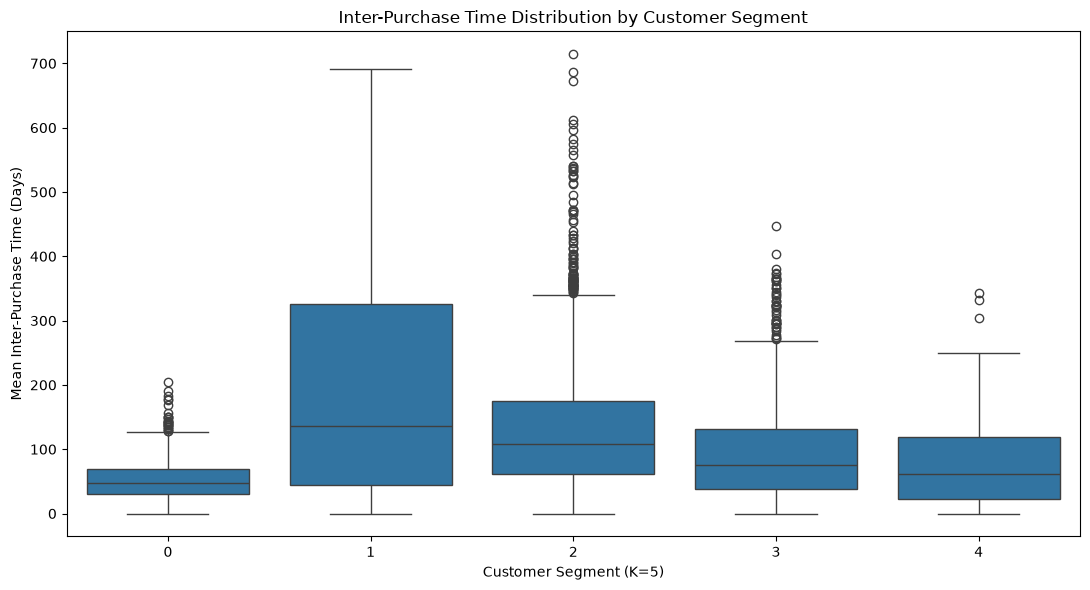

          count    mean     std  min    25%     50%     75%     max
Cluster                                                            
0        1362.0   52.14   29.68  0.0  30.31   48.25   69.40  204.97
1         298.0  190.89  169.98  0.0  43.92  135.59  325.53  690.91
2        1647.0  132.19  103.84  0.0  62.17  108.06  174.37  714.15
3         828.0   96.45   81.77  0.0  38.39   74.75  130.70  446.80
4         120.0   81.75   77.42  0.0  21.96   60.96  119.39  342.82


In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=k5_ipt,
    x="Cluster",
    y="Mean_IPT"
)

plt.title("Inter-Purchase Time Distribution by Customer Segment")
plt.xlabel("Customer Segment (K=5)")
plt.ylabel("Mean Inter-Purchase Time (Days)")
plt.tight_layout()
plt.show()

print(
    k5_ipt.groupby("Cluster")["Mean_IPT"]
    .describe()
    .round(2)
)

In [45]:
# Checking zero-day and positive-day intervals
ipt_interval_check = (
    customer_invoice_dates
    .groupby("CustomerID")["Days_Between_Purchases"]
    .agg(
        Total_Intervals="count",
        Zero_Day_Intervals=lambda x: (x == 0).sum(),
        Positive_Intervals=lambda x: (x > 0).sum()
    )
)

print("Total intervals:",
      ipt_interval_check["Total_Intervals"].sum())

print("Zero-day intervals:",
      ipt_interval_check["Zero_Day_Intervals"].sum())

print("Positive intervals:",
      ipt_interval_check["Positive_Intervals"].sum())

Total intervals: 31091
Zero-day intervals: 181
Positive intervals: 30910


In [46]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

# Fit K-Means solutions for K = 3, 4 and 5
comparison_labels = {}

for k in [3, 4, 5]:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    comparison_labels[k] = model.fit_predict(X_pca)

# Compare each pair of solutions
comparison_pairs = [(3, 4), (3, 5), (4, 5)]

comparison_results = []

for k1, k2 in comparison_pairs:

    labels1 = comparison_labels[k1]
    labels2 = comparison_labels[k2]

    ari = adjusted_rand_score(labels1, labels2)
    nmi = normalized_mutual_info_score(labels1, labels2)

    comparison_results.append({
        "Comparison": f"K={k1} vs K={k2}",
        "ARI": ari,
        "NMI": nmi
    })

ari_nmi_results = pd.DataFrame(comparison_results)

display(ari_nmi_results.round(4))

,Comparison,ARI,NMI
0,K=3 vs K=4,0.4897,0.5887
1,K=3 vs K=5,0.4070,0.5211
2,K=4 vs K=5,0.7261,0.7640


In [47]:
from scipy.stats import kruskal

# Using the original RFM values and K=5 cluster assignments
k5_data = rfm_candidates[5].join(
    k5_ipt[["Mean_IPT"]]
)

variables = [
    "Recency",
    "Frequency",
    "Monetary",
    "Mean_IPT"
]

statistical_results = []

for variable in variables:

    groups = [
        group[variable].dropna().values
        for _, group in k5_data.groupby("Cluster")
    ]

    # Kruskal-Wallis test
    statistic, p_value = kruskal(*groups)

    # Epsilon-squared effect size
    total_n = sum(len(group) for group in groups)
    number_of_groups = len(groups)

    epsilon_squared = (
        statistic - number_of_groups + 1
    ) / (total_n - number_of_groups)

    epsilon_squared = max(0, epsilon_squared)

    statistical_results.append({
        "Variable": variable,
        "Kruskal_H": statistic,
        "P_Value": p_value,
        "Epsilon_Squared": epsilon_squared,
        "Observations": total_n
    })

kruskal_results = pd.DataFrame(statistical_results)

display(kruskal_results.round(6))

,Variable,Kruskal_H,P_Value,Epsilon_Squared,Observations
0,Recency,4101.673270,0.0,0.697714,5878
1,Frequency,4872.567406,0.0,0.828975,5878
2,Monetary,4693.075165,0.0,0.798412,5878
3,Mean_IPT,749.367356,0.0,0.175381,4255


In [48]:
%pip install scikit-posthocs

import scikit_posthocs as sp

variables = ["Recency", "Frequency", "Monetary", "Mean_IPT"]

for variable in variables:

    posthoc_data = k5_ipt[
        ["Cluster", variable]
    ].dropna()

    dunn_results = sp.posthoc_dunn(
        posthoc_data,
        val_col=variable,
        group_col="Cluster",
        p_adjust="holm"
    )

    print(f"\n{'='*20} {variable} {'='*20}")
    display(dunn_results.round(5))

Note: you may need to restart the kernel to use updated packages.

==================== Recency ====================


,0,1,2,3,4
0,1.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0



==================== Frequency ====================


,0,1,2,3,4
0,1.0,0.00000,0.0,0.0,0.00000
1,0.0,1.00000,0.0,0.0,0.00025
2,0.0,0.00000,1.0,0.0,0.00000
3,0.0,0.00000,0.0,1.0,0.00000
4,0.0,0.00025,0.0,0.0,1.00000



==================== Monetary ====================


,0,1,2,3,4
0,1.0,0.00000,0.00000,0.00000,0.00000
1,0.0,1.00000,0.00000,0.00000,0.00355
2,0.0,0.00000,1.00000,0.00044,0.00000
3,0.0,0.00000,0.00044,1.00000,0.00000
4,0.0,0.00355,0.00000,0.00000,1.00000



==================== Mean_IPT ====================


,0,1,2,3,4
0,1.00000,0.00000,0.00000,0.00000,0.00208
1,0.00000,1.00000,0.44435,0.00000,0.00000
2,0.00000,0.44435,1.00000,0.00000,0.00000
3,0.00000,0.00000,0.00000,1.00000,0.04485
4,0.00208,0.00000,0.00000,0.04485,1.00000


In [49]:
# Creating a reproducible sample for hierarchical clustering

hierarchical_sample = rfm_scaled.sample(
    n=1000,
    random_state=42
)

print("Sample shape:", hierarchical_sample.shape)
print("Missing values:", hierarchical_sample.isna().sum().sum())

display(hierarchical_sample.head())

Sample shape: (1000, 3)
Missing values: 0


,Recency,Frequency,Monetary
CustomerID,,,
17777.0,-0.844894,0.034721,-0.211608
16719.0,-0.892664,1.343691,0.979326
12546.0,-0.739800,-0.412194,0.212119
17484.0,1.792013,-0.412194,-1.068417
17207.0,2.155066,-1.301428,-0.809456


In [50]:
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import pdist

# Calculating Euclidean distance matrix
euclidean_distances = pdist(
    hierarchical_sample,
    metric="euclidean"
)

# hierarchical clustering with different linkage methods
linkage_methods = ["single", "complete", "average", "ward"]

hierarchical_models = {}

for method in linkage_methods:

    Z = linkage(
        euclidean_distances,
        method=method
    )

    hierarchical_models[method] = Z

    print(f"{method.capitalize()} linkage completed.")

Single linkage completed.
Complete linkage completed.
Average linkage completed.
Ward linkage completed.


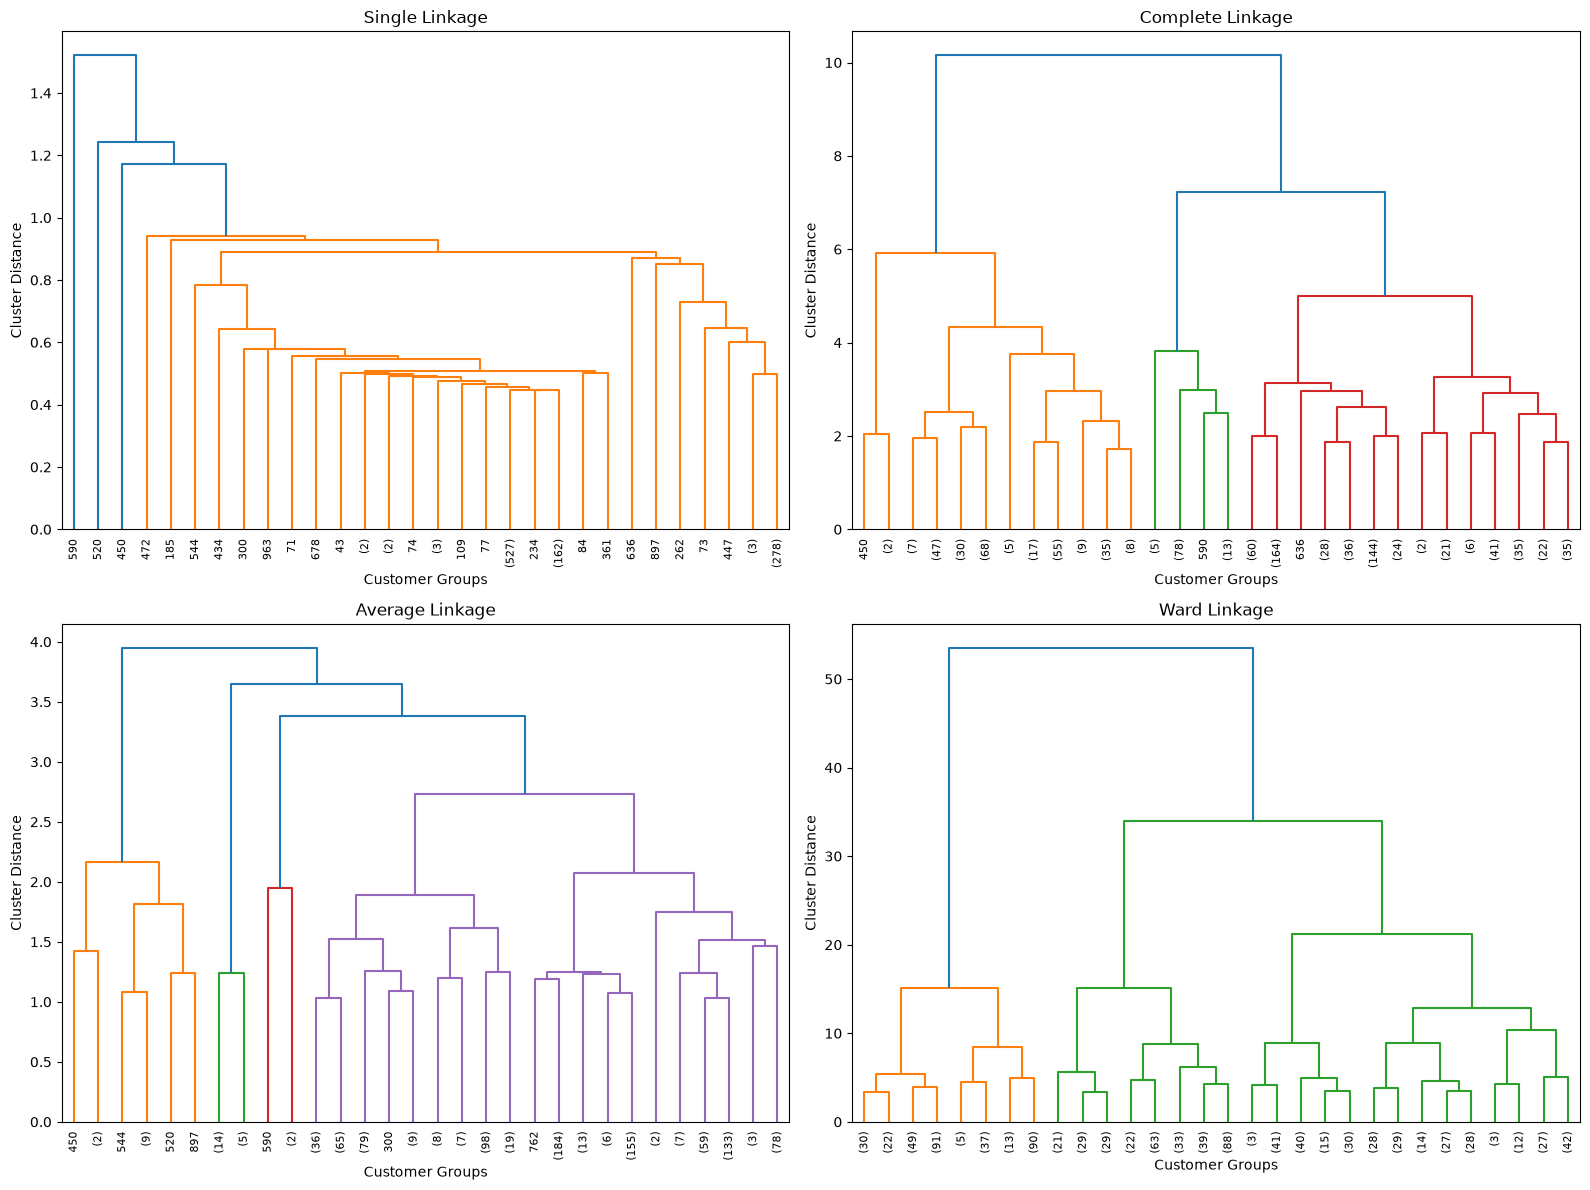

In [51]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, method in zip(axes.flatten(), linkage_methods):

    dendrogram(
        hierarchical_models[method],
        truncate_mode="lastp",
        p=30,
        leaf_rotation=90,
        leaf_font_size=8,
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Customer Groups")
    ax.set_ylabel("Cluster Distance")

plt.tight_layout()
plt.show()

In [52]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score

hierarchical_results = []

for method in linkage_methods:

    Z = hierarchical_models[method]

    labels = fcluster(
        Z,
        t=5,
        criterion="maxclust"
    )

    n_clusters = len(set(labels))

    silhouette = silhouette_score(
        hierarchical_sample,
        labels,
        metric="euclidean"
    )

    hierarchical_results.append({
        "Linkage": method,
        "Number_of_Clusters": n_clusters,
        "Silhouette_Score": silhouette
    })

hierarchical_comparison = pd.DataFrame(
    hierarchical_results
)

display(hierarchical_comparison.round(4))

,Linkage,Number_of_Clusters,Silhouette_Score
0,single,5,0.2435
1,complete,5,0.2746
2,average,5,0.2686
3,ward,5,0.3032


In [53]:
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

manhattan_distances = pdist(
    hierarchical_sample,
    metric="cityblock"
)

manhattan_linkages = ["single", "complete", "average"]

distance_results = []

for method in manhattan_linkages:

    Z = linkage(
        manhattan_distances,
        method=method
    )

    labels = fcluster(
        Z,
        t=5,
        criterion="maxclust"
    )

    score = silhouette_score(
        hierarchical_sample,
        labels,
        metric="manhattan"
    )

    distance_results.append({
        "Distance": "Manhattan",
        "Linkage": method,
        "Clusters": len(set(labels)),
        "Silhouette": score
    })

    print(f"Manhattan + {method}: {score:.4f}")

Manhattan + single: 0.1882
Manhattan + complete: 0.2673
Manhattan + average: 0.3458


In [54]:
import numpy as np
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

# sample to NumPy array
X_hier = hierarchical_sample.to_numpy()

# Calculating inverse covariance matrix
cov_matrix = np.cov(X_hier, rowvar=False)
VI = np.linalg.pinv(cov_matrix)

# Calculating Mahalanobis condensed distance matrix
mahalanobis_distances = pdist(
    X_hier,
    metric="mahalanobis",
    VI=VI
)

# Testing supported linkage methods
for method in ["single", "complete", "average"]:

    Z = linkage(
        mahalanobis_distances,
        method=method
    )

    labels = fcluster(
        Z,
        t=5,
        criterion="maxclust"
    )

    score = silhouette_score(
        X_hier,
        labels,
        metric="mahalanobis",
        VI=VI
    )

    distance_results.append({
        "Distance": "Mahalanobis",
        "Linkage": method,
        "Clusters": len(np.unique(labels)),
        "Silhouette": score
    })

print("Mahalanobis clustering completed.")

Mahalanobis clustering completed.


In [55]:
distance_comparison = pd.DataFrame(
    distance_results
)

display(
    distance_comparison
    .sort_values("Silhouette", ascending=False)
    .round(4)
)

euclidean_results = pd.DataFrame([
    {
        "Distance": "Euclidean",
        "Linkage": row["Linkage"],
        "Clusters": row["Number_of_Clusters"],
        "Silhouette": row["Silhouette_Score"]
    }
    for row in hierarchical_results
])

all_distance_results = pd.concat(
    [euclidean_results, distance_comparison],
    ignore_index=True
)

display(
    all_distance_results
    .sort_values("Silhouette", ascending=False)
    .round(4)
)

,Distance,Linkage,Clusters,Silhouette
3,Mahalanobis,single,5,0.4569
2,Manhattan,average,5,0.3458
1,Manhattan,complete,5,0.2673
5,Mahalanobis,average,5,0.2659
0,Manhattan,single,5,0.1882
4,Mahalanobis,complete,5,0.1769


,Distance,Linkage,Clusters,Silhouette
7,Mahalanobis,single,5,0.4569
6,Manhattan,average,5,0.3458
3,Euclidean,ward,5,0.3032
1,Euclidean,complete,5,0.2746
2,Euclidean,average,5,0.2686
5,Manhattan,complete,5,0.2673
9,Mahalanobis,average,5,0.2659
0,Euclidean,single,5,0.2435
4,Manhattan,single,5,0.1882
8,Mahalanobis,complete,5,0.1769


In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

# K-Means on the same 1,000-customer sample
kmeans_sample = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans_sample_labels = kmeans_sample.fit_predict(
    hierarchical_sample
)

# Ward hierarchical clustering on the same sample
euclidean_distances = pdist(
    hierarchical_sample,
    metric="euclidean"
)

ward_linkage = linkage(
    euclidean_distances,
    method="ward"
)

ward_labels = fcluster(
    ward_linkage,
    t=5,
    criterion="maxclust"
)

# Comparing the two algorithms
comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical - Ward"
    ],
    "Clusters": [
        len(np.unique(kmeans_sample_labels)),
        len(np.unique(ward_labels))
    ],
    "Silhouette": [
        silhouette_score(
            hierarchical_sample,
            kmeans_sample_labels
        ),
        silhouette_score(
            hierarchical_sample,
            ward_labels
        )
    ]
})

print(comparison)

print(
    "\nAdjusted Rand Index:",
    adjusted_rand_score(
        kmeans_sample_labels,
        ward_labels
    )
)

print(
    "Normalized Mutual Information:",
    normalized_mutual_info_score(
        kmeans_sample_labels,
        ward_labels
    )
)

             Algorithm  Clusters  Silhouette
0              K-Means         5    0.376085
1  Hierarchical - Ward         5    0.303162

Adjusted Rand Index: 0.4519363157919141
Normalized Mutual Information: 0.5996815730635225


In [57]:
hierarchical_cluster_sizes = (
    pd.Series(ward_labels)
    .value_counts()
    .sort_index()
)

hierarchical_cluster_summary = pd.DataFrame({
    "Cluster": hierarchical_cluster_sizes.index,
    "Customer_Count": hierarchical_cluster_sizes.values,
    "Percentage": (
        hierarchical_cluster_sizes.values
        / len(ward_labels) * 100
    )
})

print(hierarchical_cluster_summary.round(2))

   Cluster  Customer_Count  Percentage
0        1             192        19.2
1        2             145        14.5
2        3             324        32.4
3        4             129        12.9
4        5             210        21.0


In [58]:
# Consolidated K-Means (k=5) customer profile

k5_data = rfm_candidates[5].copy()

# Customer-level RFM profile
segment_profile = k5_data.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Mean_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),
    Mean_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Mean_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
)

# Revenue contribution
revenue = k5_data.groupby("Cluster")["Monetary"].sum()

segment_profile["Revenue"] = revenue
segment_profile["Revenue_Percentage"] = (
    revenue / k5_data["Monetary"].sum() * 100
)

segment_profile["Customer_Percentage"] = (
    segment_profile["Customer_Count"]
    / len(k5_data) * 100
)

# Inter-purchase time
segment_profile = segment_profile.join(
    ipt.groupby(k5_data["Cluster"])["Mean_IPT"].mean()
)

print(segment_profile.round(2))

         Customer_Count  Mean_Recency  Median_Recency  Mean_Frequency  \
Cluster                                                                 
0                  1362         44.63            22.0           18.01   
1                   971        118.76            79.0            1.36   
2                  1656         69.09            49.0            4.25   
3                   863        405.50           395.0            3.41   
4                  1026        526.55           521.0            1.12   

         Median_Frequency  Mean_Monetary  Median_Monetary      Revenue  \
Cluster                                                                  
0                    12.0       10002.29          4631.74  13623120.59   
1                     1.0         315.58           274.15    306431.63   
2                     4.0        1262.57          1091.52   2090808.50   
3                     3.0        1262.53           882.46   1089566.30   
4                     1.0         258.16    

In [59]:
# Checking the fitted transformation and clustering objects

print("Box-Cox lambdas:")
print(boxcox_lambdas)

print("\nStandardScaler:")
print(scaler)

print("\nPCA:")
print(pca_full)

print("\nK-Means model:")
print(candidate_models[5])

print("\nPCA input shape:", rfm_scaled.shape)
print("PCA output shape:", pca_scores.shape)

Box-Cox lambdas:
{'Frequency': np.float64(-0.2745131458318828), 'Monetary': np.float64(-0.05374579458296211)}

StandardScaler:
StandardScaler()

PCA:
PCA(n_components=3)

K-Means model:
KMeans(n_clusters=5, n_init=10, random_state=42)

PCA input shape: (5878, 3)
PCA output shape: (5878, 2)


In [60]:
import joblib
from pathlib import Path

# project root
project_root = (
    Path.cwd().parent
    if Path.cwd().name.lower() in ["notebook", "notebooks"]
    else Path.cwd()
)

# Creating models directory
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Selecting final K-Means model
final_kmeans = candidate_models[5]

# Check model compatibility
assert final_kmeans.n_clusters == 5
assert final_kmeans.n_features_in_ == 2
assert pca_full.n_components == 3
assert len(pca_scores.columns) == 2

# Storing all fitted objects together
model_artifacts = {
    "boxcox_lambdas": {
        column: float(value)
        for column, value in boxcox_lambdas.items()
    },
    "scaler": scaler,
    "pca": pca_full,
    "kmeans": final_kmeans,
    "cluster_names": {
        0: "High-Value Loyal Customers",
        1: "Recent One-Time / Low-Frequency Customers",
        2: "Regular Moderate-Value Customers",
        3: "Dormant Repeat Customers",
        4: "Long-Inactive Low-Value Customers"
    },
    "reference_date": reference_date,
    "features": ["Recency", "Frequency", "Monetary"],
    "pca_components_used": 2,
    "n_clusters": 5
}

# Saving artifacts
model_path = models_dir / "customer_segmentation_model.joblib"

joblib.dump(model_artifacts, model_path)

print("Model successfully saved!")
print("Location:", model_path)
print("File size:", round(model_path.stat().st_size / 1024, 2), "KB")

Model successfully saved!
Location: d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\models\customer_segmentation_model.joblib
File size: 26.04 KB


In [61]:
# Model validation and prediction using the saved artifacts

import joblib
import numpy as np
from sklearn.metrics import accuracy_score

loaded_artifacts = joblib.load(model_path)

loaded_scaler = loaded_artifacts["scaler"]
loaded_pca = loaded_artifacts["pca"]
loaded_kmeans = loaded_artifacts["kmeans"]

loaded_lambdas = loaded_artifacts["boxcox_lambdas"]

rfm_test = rfm.copy()

from scipy.stats import boxcox

rfm_test["Frequency"] = boxcox(
    rfm_test["Frequency"],
    lmbda=loaded_lambdas["Frequency"]
)

rfm_test["Monetary"] = boxcox(
    rfm_test["Monetary"],
    lmbda=loaded_lambdas["Monetary"]
)

# Applying the saved scaler
scaled_test = loaded_scaler.transform(
    rfm_test[["Recency", "Frequency", "Monetary"]]
)

# Applying saved PCA and retain first two components
pca_test = loaded_pca.transform(scaled_test)[:, :2]

# Predicting customer clusters
predicted_labels = loaded_kmeans.predict(pca_test)

# Comparing with original K-Means assignments
original_labels = candidate_labels[5]

print("Loaded model:", type(loaded_kmeans).__name__)
print("Number of predictions:", len(predicted_labels))

print(
    "Prediction agreement:",
    accuracy_score(original_labels, predicted_labels) * 100,
    "%"
)

print(
    "All predictions identical:",
    np.array_equal(original_labels, predicted_labels)
)

Loaded model: KMeans
Number of predictions: 5878
Prediction agreement: 100.0 %
All predictions identical: True


d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
d:\DataAnalysis\Projects\IDEAS_TIH_CustomerSegmentation\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [1]:

import pandas as pd
from pathlib import Path

# Load the cleaned transaction dataset
cleaned_data_path = Path("../data/processed/cleaned_purchases.csv")

purchases = pd.read_csv(
    cleaned_data_path,
    usecols=["CustomerID", "InvoiceNo", "InvoiceDate"],
    parse_dates=["InvoiceDate"]
)

# Keep one record per customer per invoice
customer_invoices = (
    purchases
    .drop_duplicates(subset=["CustomerID", "InvoiceNo"])
    .sort_values(["CustomerID", "InvoiceDate"])
    .copy()
)

# Calculate days between consecutive invoices
customer_invoices["Days_Between_Purchases"] = (
    customer_invoices
    .groupby("CustomerID")["InvoiceDate"]
    .diff()
    .dt.total_seconds() / 86400
)

# Calculate each customer's mean purchase interval
customer_ipt = (
    customer_invoices
    .groupby("CustomerID")["Days_Between_Purchases"]
    .mean()
    .reset_index()
)

# Save the smaller derived dataset
output_path = Path("../data/processed/customer_purchase_intervals.csv")

customer_ipt.to_csv(output_path, index=False)

print("Derived dataset created successfully!")
print(customer_ipt.shape)
print(f"File saved at: {output_path}")


Derived dataset created successfully!
(5878, 2)
File saved at: ..\data\processed\customer_purchase_intervals.csv
